<a href="https://colab.research.google.com/github/lawalidris001/Potato-Diseases-Classification-Using-CNN/blob/main/PotatoDiseaseClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt


In [ ]:
IMAGE_SIZE = 256
BATCH_SIZE = 32
CHANNEL = 3
EPOCH = 50

In [ ]:
potato_ds = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/drive/MyDrive/PlantVillage",
    shuffle=True,
    image_size =(IMAGE_SIZE, IMAGE_SIZE),
    batch_size = BATCH_SIZE

)

Found 2152 files belonging to 3 classes.


In [ ]:
class_names = potato_ds.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [ ]:
len(potato_ds)

68

In [ ]:
for image_batch, label_batch in potato_ds.take(1):
  print(image_batch.shape)
  print(label_batch.shape)

(32, 256, 256, 3)
(32,)


In [ ]:
for image_batch, label_batch in potato_ds.take(1):
  print(image_batch[0].shape)
  print(image_batch[0])



(256, 256, 3)
tf.Tensor(
[[[131. 119. 123.]
  [120. 108. 112.]
  [134. 122. 126.]
  ...
  [113. 101. 105.]
  [113. 101. 105.]
  [112. 100. 104.]]

 [[115. 103. 107.]
  [112. 100. 104.]
  [115. 103. 107.]
  ...
  [119. 107. 111.]
  [118. 106. 110.]
  [117. 105. 109.]]

 [[117. 105. 109.]
  [111.  99. 103.]
  [115. 103. 107.]
  ...
  [127. 115. 119.]
  [123. 111. 115.]
  [119. 107. 111.]]

 ...

 [[168. 159. 164.]
  [164. 155. 160.]
  [161. 152. 157.]
  ...
  [174. 165. 170.]
  [171. 162. 167.]
  [166. 157. 162.]]

 [[164. 155. 160.]
  [165. 156. 161.]
  [166. 157. 162.]
  ...
  [171. 162. 167.]
  [170. 161. 166.]
  [166. 157. 162.]]

 [[160. 151. 156.]
  [166. 157. 162.]
  [170. 161. 166.]
  ...
  [167. 158. 163.]
  [168. 159. 164.]
  [167. 158. 163.]]], shape=(256, 256, 3), dtype=float32)


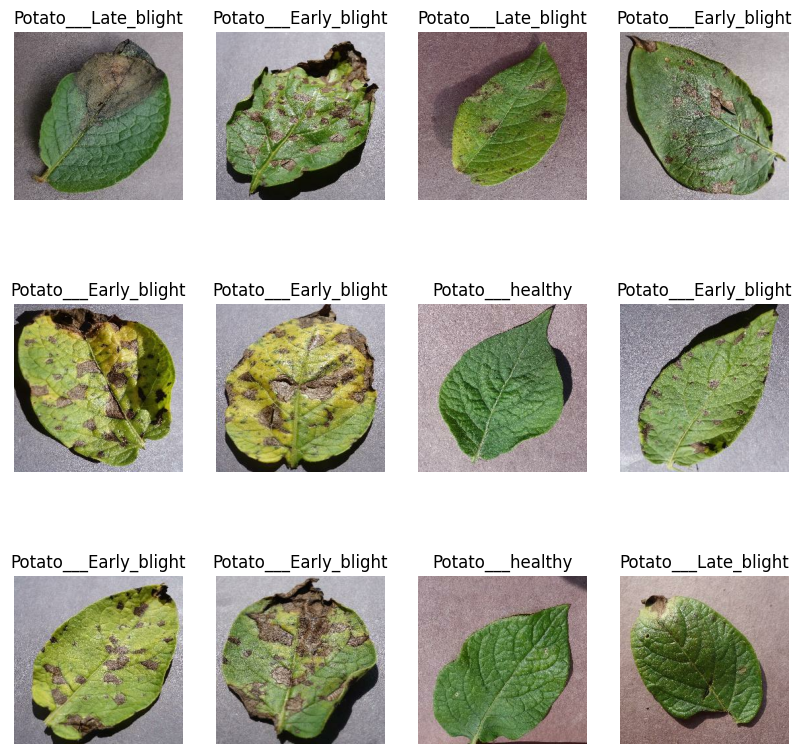

In [ ]:
plt.figure(figsize=(10, 10))

for image_batch, label_batch in potato_ds.take(1):
    for i in range(12):
        plt.subplot(3,4, i+ 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

In [ ]:
train_size = 0.8
len(potato_ds)*0.8

54.400000000000006

In [ ]:
# train_ds = potato_ds.take(54)

# len(train_ds)

In [ ]:
remain_ds = potato_ds.skip(54)

len(remain_ds)

14

In [ ]:
test_ds = 0.1

len(potato_ds)*0.1

6.800000000000001

In [ ]:
# test_ds = remain_ds.take(6)

In [ ]:
# val_ds = remain_ds.take(6)

In [ ]:
def get_dataset_partition(ds, train_split= 0.8, test_split = 0.1, val_split = 0.1, shuffle = True, shuffle_size = 10000 ):
  ds_size = len(potato_ds)
  if shuffle:
     ds.shuffle(shuffle_size, seed = 12)


  train_size = int(train_split * ds_size)
  val_size = int(val_split * ds_size)

  train_ds = potato_ds.take(train_size)

  val_ds = potato_ds.skip(train_size).take(val_size)
  test_ds = potato_ds.skip(train_size).skip(val_size)

  return train_ds, val_ds, test_ds

In [ ]:
train_ds, val_ds, test_ds = get_dataset_partition(potato_ds)

In [ ]:
len(train_ds)

54

In [ ]:
len(test_ds)

8

In [ ]:
len(val_ds)

6

In [ ]:
train_ds= train_ds.cache().shuffle(1000).prefetch(buffer_size =tf.data.AUTOTUNE)
val_ds= val_ds.cache().shuffle(1000).prefetch(buffer_size =tf.data.AUTOTUNE)
test_ds= test_ds.cache().shuffle(1000).prefetch(buffer_size =tf.data.AUTOTUNE)

In [ ]:
resize_and_rescale = tf.keras.Sequential([
    tf.keras.layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    tf.keras.layers.Rescaling(1.0/255)

])



In [ ]:
data_augentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),

])

In [ ]:
n_classes = 3
input_shape =   (IMAGE_SIZE, IMAGE_SIZE, CHANNEL)

model = models.Sequential([
    tf.keras.layers.Input(shape=input_shape),
    resize_and_rescale,
    data_augentation,
    layers.Conv2D(32, (3,3), activation= "relu", input_shape = input_shape),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation= "relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation= "relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation= "relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation= "relu"),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation= "relu"),
    layers.MaxPooling2D(2,2),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(n_classes, activation="softmax")


])

# model.build(input_shape= input_shape)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer = "adam",
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics = ["accuracy"]
)

In [ ]:
history = model.fit(
    train_ds,
    epochs = EPOCH,
    batch_size = BATCH_SIZE,
    verbose = 1,
    validation_data = val_ds

)

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 268s 731ms/step - accuracy: 0.4676 - loss: 0.9051 - val_accuracy: 0.4323 - val_loss: 0.9444
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.6105 - loss: 0.7936 - val_accuracy: 0.6927 - val_loss: 0.6655
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.7755 - loss: 0.5506 - val_accuracy: 0.7552 - val_loss: 0.5585
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.8212 - loss: 0.4391 - val_accuracy: 0.8177 - val_loss: 0.4077
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.8628 - loss: 0.3354 - val_accuracy: 0.8698 - val_loss: 0.3248
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.9028 - loss: 0.2755 - val_accuracy: 0.8490 - val_loss: 0.3488
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.8964 - loss: 0.2825 - val_accuracy: 0.7708 - val_loss: 0.4331
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9126 - loss: 0.2299 - val_accuracy: 0.8021 

In [ ]:
scores =model.evaluate(test_ds)
scores

8/8 ━━━━━━━━━━━━━━━━━━━━ 28s 20ms/step - accuracy: 0.9957 - loss: 0.0154


[0.015368133783340454, 0.9956896305084229]

In [ ]:
history

In [ ]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [ ]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]


loss= history.history["loss"]
val_loss = history.history["val_loss"]



Text(0.5, 1.0, 'Training and Validation Accuracy')

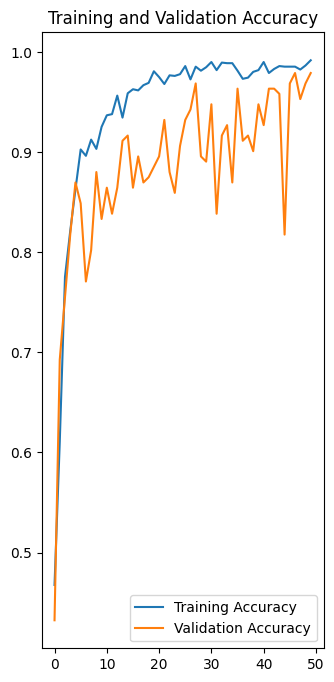

In [ ]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCH), acc, label='Training Accuracy')
plt.plot(range(EPOCH), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')


In [ ]:
for images_batch, labels_batch in test_ds(1):
  print(images_batch[0].numpy())